# Modelos supervisionados — Triagem de óbito nas CATs do Ceará

Treinamento, ajuste e avaliação de **KNN**, **Árvore de Decisão**, **Random Forest** e **MLP** para prever **Indica Óbito Acidente** (`Sim = 1`, `Não = 0`) a partir das bases preparadas por `02_pre_processamento.ipynb` (`datasets/processados/treino.csv` e `teste.csv`).

A análise completa e as discussões detalhadas estão em [`relatorio_modelos_supervisionados.md`](relatorio_modelos_supervisionados.md).

## 1. Bibliotecas e scripts

Importamos os módulos de treinamento em `scripts/` (`knn.py`, `arvore_decisao.py`, `random_forest.py` e `mlp.py`) e as ferramentas do `scikit-learn`.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import (
    SelectKBest,
    VarianceThreshold,
    chi2,
    mutual_info_classif,
)
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from scripts.arvore_decisao import (
    FAMILIA as FAMILIA_ARVORE,
    configuracoes as configuracoes_arvore,
    treinar_arvore_decisao,
)
from scripts.knn import (
    FAMILIA as FAMILIA_KNN,
    configuracoes as configuracoes_knn,
    treinar_knn,
)
from scripts.mlp import (
    FAMILIA as FAMILIA_MLP,
    configuracoes as configuracoes_mlp,
    treinar_mlp,
)
from scripts.random_forest import (
    FAMILIA as FAMILIA_RF,
    configuracoes as configuracoes_rf,
    treinar_random_forest,
)

SEMENTE = 42
PASTA_DADOS_PREPARADOS = Path("datasets/processados")
PASTA_FIGURAS = Path("figuras/atividade_03")
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

## 2. Carregamento das bases preparadas

Lemos `treino.csv` (5.760 registros, 22 óbitos) e `teste.csv` (1.441 registros, 5 óbitos) gerados em `02_pre_processamento.ipynb`, com as cinco entradas categóricas de triagem (`Tipo do Acidente`, `Agente  Causador  Acidente`, `Parte Corpo Atingida`, `Natureza da Lesão` e `Sexo`).

In [2]:
caminho_treino = PASTA_DADOS_PREPARADOS / "treino.csv"
caminho_teste = PASTA_DADOS_PREPARADOS / "teste.csv"

if not caminho_treino.exists() or not caminho_teste.exists():
    raise FileNotFoundError(
        "Bases preparadas não encontradas em datasets/processados/. "
        "Execute primeiro o notebook 02_pre_processamento.ipynb para gerar treino.csv e teste.csv."
    )

df_treino = pd.read_csv(
    caminho_treino,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8",
)
df_teste = pd.read_csv(
    caminho_teste,
    dtype="string",
    keep_default_na=False,
    encoding="utf-8",
)

coluna_alvo = "Indica Óbito Acidente"
colunas_categoricas = [
    "Tipo do Acidente",
    "Agente  Causador  Acidente",
    "Parte Corpo Atingida",
    "Natureza da Lesão",
    "Sexo",
]

X_train = df_treino[colunas_categoricas].copy()
X_test = df_teste[colunas_categoricas].copy()

y_train_texto = df_treino[coluna_alvo].str.strip()
y_test_texto = df_teste[coluna_alvo].str.strip()

y_train = y_train_texto.map({"Não": 0, "Sim": 1}).astype(int)
y_test = y_test_texto.map({"Não": 0, "Sim": 1}).astype(int)

y_total_texto = pd.concat([y_train_texto, y_test_texto], ignore_index=True)
distribuicao = pd.DataFrame({
    "quantidade": y_total_texto.value_counts(),
    "percentual (%)": (100 * y_total_texto.value_counts(normalize=True)).round(2),
})

print(f"Base de treino carregada: {X_train.shape}")
print(f"Base de teste carregada:  {X_test.shape}")
display(distribuicao)
display(X_train.head())

Base de treino carregada: (5760, 5)
Base de teste carregada:  (1441, 5)


,quantidade,percentual (%)
Indica Óbito Acidente,,
Não,7174,99.63
Sim,27,0.37


,Tipo do Acidente,Agente Causador Acidente,Parte Corpo Atingida,Natureza da Lesão,Sexo
0,Típico,309000000,Mao (Exceto Punho ou,Lesao Imediata,Masculino
1,Trajeto,302010200,"Membros Superiores,",Fratura,Masculino
2,Típico,305028000,Perna (Entre O Torno,"Contusao, Esmagament",Feminino
3,Típico,305032500,Pe (Exceto Artelhos),Fratura,Masculino
4,Típico,302010350,Pe (Exceto Artelhos),"Distensao, Torcao",Feminino


## 3. Conferência da divisão treino/teste

Conferimos a proporção de classes da partição estratificada 80/20 (`random_state=42`). O teste fica reservado até a seção 15.

In [3]:
resumo_divisao = pd.DataFrame(
    {
        "registros": [len(y_train), len(y_test)],
        "sem_obito (0)": [int((y_train == 0).sum()), int((y_test == 0).sum())],
        "com_obito (1)": [int((y_train == 1).sum()), int((y_test == 1).sum())],
        "percentual_obito (%)": [
            round(100 * y_train.mean(), 2),
            round(100 * y_test.mean(), 2),
        ],
    },
    index=["Treino (80%)", "Teste (20%)"],
)

display(resumo_divisao)

,registros,sem_obito (0),com_obito (1),percentual_obito (%)
Treino (80%),5760,5738,22,0.38
Teste (20%),1441,1436,5,0.35


## 4. Validação cruzada e representações da etapa 2

Usamos `StratifiedKFold(n_splits=5)` sobre o treino. Dentro de cada fold, ajustamos exclusivamente no treino do fold cinco representações da etapa 2: **One-hot completo**, **Qui-quadrado (`k=50`)**, **Informação mútua (`k=50`)**, **Embutido (Árvore)** e **PCA (`90%`)**.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

REPRESENTACOES = [
    "One-hot completo",
    "Qui-quadrado (k=50)",
    "Informação mútua (k=50)",
    "Embutido (Árvore)",
    "PCA (90%)",
]


def construir_representacao(nome_rep, X_tr_cat, y_tr, X_av_cat, semente=SEMENTE):
    """Ajusta one-hot e eventual redução apenas em (X_tr_cat, y_tr) e transforma ambos."""
    encoder = OneHotEncoder(handle_unknown="ignore")
    X_tr_ohe = encoder.fit_transform(X_tr_cat).toarray()
    X_av_ohe = encoder.transform(X_av_cat).toarray()
    nomes_ohe = encoder.get_feature_names_out()

    filtro_var = VarianceThreshold(threshold=0.0)
    X_tr_base = filtro_var.fit_transform(X_tr_ohe)
    X_av_base = filtro_var.transform(X_av_ohe)
    nomes_base = nomes_ohe[filtro_var.get_support()]

    if nome_rep == "One-hot completo":
        return X_tr_base, X_av_base, nomes_base

    if nome_rep == "Qui-quadrado (k=50)":
        k = min(50, X_tr_base.shape[1])
        seletor = SelectKBest(score_func=chi2, k=k)
        X_tr_sel = seletor.fit_transform(X_tr_base, y_tr)
        X_av_sel = seletor.transform(X_av_base)
        return X_tr_sel, X_av_sel, nomes_base[seletor.get_support()]

    if nome_rep == "Informação mútua (k=50)":
        k = min(50, X_tr_base.shape[1])
        seletor = SelectKBest(
            score_func=lambda X_, y_: mutual_info_classif(
                X_,
                y_,
                discrete_features=True,
                random_state=semente,
            ),
            k=k,
        )
        X_tr_sel = seletor.fit_transform(X_tr_base, y_tr)
        X_av_sel = seletor.transform(X_av_base)
        return X_tr_sel, X_av_sel, nomes_base[seletor.get_support()]

    if nome_rep == "Embutido (Árvore)":
        arvore_sel = DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=8,
            class_weight="balanced",
            random_state=semente,
        )
        arvore_sel.fit(X_tr_base, y_tr)
        mascara = arvore_sel.feature_importances_ > 0
        if not np.any(mascara):
            mascara = np.ones(X_tr_base.shape[1], dtype=bool)
        return X_tr_base[:, mascara], X_av_base[:, mascara], nomes_base[mascara]

    if nome_rep == "PCA (90%)":
        scaler = StandardScaler()
        X_tr_std = scaler.fit_transform(X_tr_base)
        X_av_std = scaler.transform(X_av_base)
        pca = PCA(n_components=0.90, svd_solver="full")
        X_tr_pca = pca.fit_transform(X_tr_std)
        X_av_pca = pca.transform(X_av_std)
        nomes_pca = np.array([f"CP{i + 1}" for i in range(pca.n_components_)])
        return X_tr_pca, X_av_pca, nomes_pca

    raise ValueError(f"Representação desconhecida: {nome_rep}")


def preparar_folds_representacoes(representacoes, X_treino_cat, y_treino_bin, validador):
    """Pré-computa os 5 folds estratificados para cada representação, sem vazamento."""
    divisoes = list(validador.split(X_treino_cat, y_treino_bin))
    folds_por_rep = {rep: [] for rep in representacoes}

    for idx_tr, idx_val in divisoes:
        X_f_tr_cat = X_treino_cat.iloc[idx_tr]
        X_f_val_cat = X_treino_cat.iloc[idx_val]
        y_f_tr = y_treino_bin.iloc[idx_tr].to_numpy()
        y_f_val = y_treino_bin.iloc[idx_val].to_numpy()

        for rep in representacoes:
            X_f_tr, X_f_val, nomes_cols = construir_representacao(
                rep, X_f_tr_cat, y_f_tr, X_f_val_cat
            )
            folds_por_rep[rep].append({
                "idx_tr": idx_tr,
                "idx_val": idx_val,
                "X_tr": X_f_tr,
                "X_val": X_f_val,
                "y_tr": y_f_tr,
                "y_val": y_f_val,
                "n_colunas": len(nomes_cols),
            })

    return folds_por_rep


folds_por_representacao = preparar_folds_representacoes(
    REPRESENTACOES, X_train, y_train, cv
)

resumo_representacoes = pd.DataFrame([
    {
        "representacao": rep,
        "colunas_media_folds": round(
            float(np.mean([f["n_colunas"] for f in folds_por_representacao[rep]])), 1
        ),
        "colunas_min_fold": min(f["n_colunas"] for f in folds_por_representacao[rep]),
        "colunas_max_fold": max(f["n_colunas"] for f in folds_por_representacao[rep]),
    }
    for rep in REPRESENTACOES
])

display(resumo_representacoes)


def probabilidade_positiva(modelo, X_matriz):
    """Retorna a probabilidade estimada para a classe positiva (1)."""
    probs = modelo.predict_proba(X_matriz)
    classes = list(modelo.classes_)
    if 1 in classes:
        return probs[:, classes.index(1)]
    return np.zeros(len(X_matriz), dtype=float)


def calcular_metricas(y_real, y_prob, limiar=0.5):
    """Calcula métricas globais, por limiar e contagens da matriz de confusão."""
    y_real_arr = np.asarray(y_real, dtype=int)
    y_prob_arr = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob_arr >= limiar).astype(int)

    vn, fp, fn, vp = confusion_matrix(y_real_arr, y_pred, labels=[0, 1]).ravel()
    duas_classes = len(np.unique(y_real_arr)) == 2

    return {
        "acuracia": accuracy_score(y_real_arr, y_pred),
        "precisao": precision_score(y_real_arr, y_pred, zero_division=0),
        "recall": recall_score(y_real_arr, y_pred, zero_division=0),
        "f1": f1_score(y_real_arr, y_pred, zero_division=0),
        "f2": fbeta_score(y_real_arr, y_pred, beta=2, zero_division=0),
        "pct_alertas": 100.0 * float(y_pred.mean()),
        "roc_auc": roc_auc_score(y_real_arr, y_prob_arr) if duas_classes else np.nan,
        "average_precision": (
            average_precision_score(y_real_arr, y_prob_arr) if duas_classes else np.nan
        ),
        "vp": int(vp),
        "fp": int(fp),
        "vn": int(vn),
        "fn": int(fn),
    }


def melhor_limiar_f1(y_real, y_prob):
    """Encontra o limiar que maximiza o F1-score sobre probabilidades de validação."""
    precisoes, recalls, limiares = precision_recall_curve(y_real, y_prob)
    if len(limiares) == 0:
        return 0.5
    f1s = (
        2
        * precisoes[:-1]
        * recalls[:-1]
        / np.maximum(precisoes[:-1] + recalls[:-1], 1e-12)
    )
    if np.max(f1s) <= 0:
        return 0.5
    return float(limiares[int(np.argmax(f1s))])


def melhor_limiar_fbeta(y_real, y_prob, beta=2.0):
    """Encontra o limiar que maximiza o F-beta score sobre probabilidades de validação."""
    precisoes, recalls, limiares = precision_recall_curve(y_real, y_prob)
    if len(limiares) == 0:
        return 0.5
    b2 = beta ** 2
    fbetas = (
        (1 + b2)
        * precisoes[:-1]
        * recalls[:-1]
        / np.maximum(b2 * precisoes[:-1] + recalls[:-1], 1e-12)
    )
    if np.max(fbetas) <= 0:
        return 0.5
    return float(limiares[int(np.argmax(fbetas))])


def limiar_recall_minimo(y_real, y_prob, recall_alvo=0.80):
    """Retorna o maior limiar (menos falsos positivos) que ainda atinge recall >= recall_alvo."""
    _, recalls, limiares = precision_recall_curve(y_real, y_prob)
    if len(limiares) == 0:
        return 0.5
    validos = np.where(recalls[:-1] >= recall_alvo)[0]
    if len(validos) == 0:
        return float(limiares[0])
    return float(limiares[int(validos[-1])])


def formatar_parametros(params):
    """Formata um dicionário de hiperparâmetros para exibição em tabela."""
    pares = [
        f"{chave}={valor}"
        for chave, valor in params.items()
        if chave not in {"random_state", "n_jobs"}
    ]
    return ", ".join(pares) if pares else "padrão"


def avaliar_modelo_cv(
    familia,
    funcao_treino,
    grade_parametros,
    folds_por_rep,
    representacoes,
    tamanho_treino,
):
    """Executa validação cruzada estratificada sobre as representações e hiperparâmetros."""
    linhas = []
    oof_por_config = {}
    id_cfg = 0

    for nome_rep in representacoes:
        folds = folds_por_rep[nome_rep]
        for params in grade_parametros:
            metricas_val = []
            metricas_treino = []
            oof_prob = np.zeros(tamanho_treino, dtype=float)
            avisos_convergencia = 0

            for fold in folds:
                X_f_tr = fold["X_tr"]
                X_f_val = fold["X_val"]
                y_f_tr = fold["y_tr"]
                y_f_val = fold["y_val"]

                with warnings.catch_warnings(record=True) as registro_avisos:
                    warnings.simplefilter("always", ConvergenceWarning)
                    modelo = funcao_treino(X_f_tr, y_f_tr, **params)

                avisos_convergencia += sum(
                    issubclass(a.category, ConvergenceWarning) for a in registro_avisos
                )

                prob_tr = probabilidade_positiva(modelo, X_f_tr)
                prob_val = probabilidade_positiva(modelo, X_f_val)
                oof_prob[fold["idx_val"]] = prob_val

                metricas_treino.append(calcular_metricas(y_f_tr, prob_tr))
                metricas_val.append(calcular_metricas(y_f_val, prob_val))

            df_tr = pd.DataFrame(metricas_treino)
            df_val = pd.DataFrame(metricas_val)
            oof_por_config[id_cfg] = oof_prob

            linhas.append({
                "familia": familia,
                "representacao": nome_rep,
                "id_config": id_cfg,
                "parametros_texto": formatar_parametros(params),
                "parametros": params,
                "average_precision_val": df_val["average_precision"].mean(),
                "desvio_ap_val": df_val["average_precision"].std(),
                "roc_auc_val": df_val["roc_auc"].mean(),
                "desvio_auc_val": df_val["roc_auc"].std(),
                "f1_val": df_val["f1"].mean(),
                "precisao_val": df_val["precisao"].mean(),
                "recall_val": df_val["recall"].mean(),
                "acuracia_val": df_val["acuracia"].mean(),
                "average_precision_treino": df_tr["average_precision"].mean(),
                "roc_auc_treino": df_tr["roc_auc"].mean(),
                "f1_treino": df_tr["f1"].mean(),
                "avisos_convergencia": avisos_convergencia,
            })
            id_cfg += 1

    tabela = pd.DataFrame(linhas).sort_values(
        ["average_precision_val", "roc_auc_val", "f1_val"],
        ascending=[False, False, False],
        ignore_index=True,
    )
    return tabela, oof_por_config


COLUNAS_TABELA = [
    "representacao",
    "parametros_texto",
    "average_precision_val",
    "roc_auc_val",
    "f1_val",
    "precisao_val",
    "recall_val",
    "acuracia_val",
    "roc_auc_treino",
]

,representacao,colunas_media_folds,colunas_min_fold,colunas_max_fold
0,One-hot completo,220.4,218,224
1,Qui-quadrado (k=50),50.0,50,50
2,Informação mútua (k=50),50.0,50,50
3,Embutido (Árvore),10.8,10,12
4,PCA (90%),179.4,178,182


# Parte I — Representações e ajuste das famílias

## 5. Referência majoritária

Piso de comparação com `DummyClassifier(strategy="prior")`.

In [5]:
def treinar_referencia(X_treino, y_treino):
    """Treina o classificador de referência pela frequência das classes no treino."""
    modelo = DummyClassifier(strategy="prior")
    modelo.fit(X_treino, y_treino)
    return modelo


res_referencia, oof_referencia = avaliar_modelo_cv(
    "Referência (Majoritário)",
    treinar_referencia,
    [{}],
    folds_por_representacao,
    ["One-hot completo"],
    len(y_train),
)

display(res_referencia[COLUNAS_TABELA].round(4))

,representacao,parametros_texto,average_precision_val,roc_auc_val,f1_val,precisao_val,recall_val,acuracia_val,roc_auc_treino
0,One-hot completo,padrão,0.0038,0.5,0.0,0.0,0.0,0.9962,0.5


### 5.1 Comparação das representações da etapa 2 por família

Avaliamos as 5 representações com os parâmetros padrão de cada família para escolher a melhor representação de cada uma.

Average Precision (CV) por família × representação (parâmetros padrão):


representacao,One-hot completo,Qui-quadrado (k=50),Informação mútua (k=50),Embutido (Árvore),PCA (90%)
familia,,,,,
KNN,0.1030,0.0793,0.0881,0.1633,0.1345
Árvore de decisão,0.0621,0.0610,0.0604,0.0621,0.0192
Random Forest,0.2106,0.2103,0.2166,0.1572,0.1693
MLP,0.2867,0.2743,0.2394,0.2301,0.1885



ROC-AUC (CV) por família × representação (parâmetros padrão):


representacao,One-hot completo,Qui-quadrado (k=50),Informação mútua (k=50),Embutido (Árvore),PCA (90%)
familia,,,,,
KNN,0.6104,0.5866,0.5862,0.6052,0.6459
Árvore de decisão,0.6691,0.7134,0.7130,0.6691,0.6362
Random Forest,0.9017,0.9007,0.9030,0.7743,0.8936
MLP,0.9200,0.9168,0.9202,0.8195,0.8750



Representação escolhida por família para o ajuste de hiperparâmetros:


,familia,representacao_selecionada,ap_cv_padrao,ap_cv_onehot,auc_cv_padrao
0,KNN,Embutido (Árvore),0.1633,0.1030,0.6052
1,Árvore de decisão,One-hot completo,0.0621,0.0621,0.6691
2,Random Forest,Informação mútua (k=50),0.2166,0.2106,0.9030
3,MLP,One-hot completo,0.2867,0.2867,0.9200


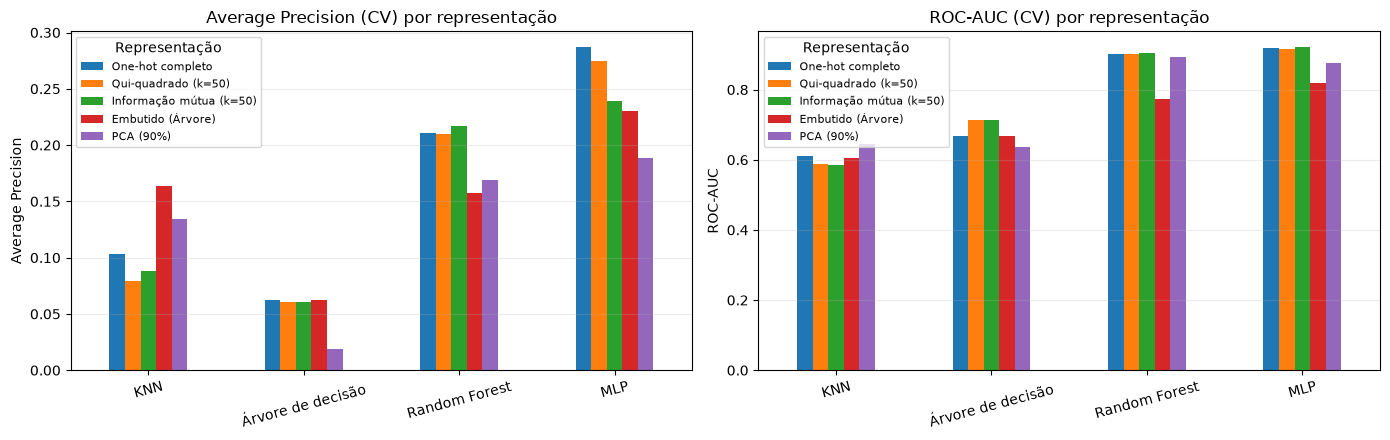

In [6]:
familias_padrao = [
    (FAMILIA_KNN, treinar_knn, [{}]),
    (FAMILIA_ARVORE, treinar_arvore_decisao, [{"random_state": SEMENTE}]),
    (FAMILIA_RF, treinar_random_forest, [{"random_state": SEMENTE}]),
    (FAMILIA_MLP, treinar_mlp, [{"random_state": SEMENTE}]),
]

tabelas_rep = []
melhor_rep_por_familia = {}

for nome_fam, fn_treino, grade_padrao in familias_padrao:
    tab_rep, _ = avaliar_modelo_cv(
        nome_fam,
        fn_treino,
        grade_padrao,
        folds_por_representacao,
        REPRESENTACOES,
        len(y_train),
    )
    tabelas_rep.append(tab_rep)
    melhor_rep_por_familia[nome_fam] = tab_rep.iloc[0]["representacao"]

comp_representacoes = pd.concat(tabelas_rep, ignore_index=True)
ordem_familias = [FAMILIA_KNN, FAMILIA_ARVORE, FAMILIA_RF, FAMILIA_MLP]

pivot_ap = (
    comp_representacoes.pivot(
        index="familia", columns="representacao", values="average_precision_val"
    )
    .reindex(index=ordem_familias, columns=REPRESENTACOES)
)
pivot_auc = (
    comp_representacoes.pivot(
        index="familia", columns="representacao", values="roc_auc_val"
    )
    .reindex(index=ordem_familias, columns=REPRESENTACOES)
)

print("Average Precision (CV) por família × representação (parâmetros padrão):")
display(pivot_ap.round(4))
print("\nROC-AUC (CV) por família × representação (parâmetros padrão):")
display(pivot_auc.round(4))

escolha_rep_df = pd.DataFrame([
    {
        "familia": fam,
        "representacao_selecionada": melhor_rep_por_familia[fam],
        "ap_cv_padrao": float(pivot_ap.loc[fam, melhor_rep_por_familia[fam]]),
        "ap_cv_onehot": float(pivot_ap.loc[fam, "One-hot completo"]),
        "auc_cv_padrao": float(pivot_auc.loc[fam, melhor_rep_por_familia[fam]]),
    }
    for fam in ordem_familias
])
print("\nRepresentação escolhida por família para o ajuste de hiperparâmetros:")
display(escolha_rep_df.round(4))

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5))
pivot_ap.plot(kind="bar", ax=eixos[0])
pivot_auc.plot(kind="bar", ax=eixos[1])

eixos[0].set(
    title="Average Precision (CV) por representação",
    xlabel="",
    ylabel="Average Precision",
)
eixos[1].set(
    title="ROC-AUC (CV) por representação",
    xlabel="",
    ylabel="ROC-AUC",
)

for eixo in eixos:
    eixo.tick_params(axis="x", rotation=15)
    eixo.grid(axis="y", alpha=0.25)
    eixo.legend(title="Representação", fontsize=8)

plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "comparacao_representacoes_cv.png", dpi=135)
plt.show()

## 6. K-Nearest Neighbors (KNN)

Busca de hiperparâmetros (`n_neighbors` e `weights`) sobre a melhor representação do KNN.

In [7]:
res_knn, oof_knn = avaliar_modelo_cv(
    FAMILIA_KNN,
    treinar_knn,
    configuracoes_knn(),
    folds_por_representacao,
    [melhor_rep_por_familia[FAMILIA_KNN]],
    len(y_train),
)

display(res_knn[COLUNAS_TABELA].round(4))

,representacao,parametros_texto,average_precision_val,roc_auc_val,f1_val,precisao_val,recall_val,acuracia_val,roc_auc_treino
0,Embutido (Árvore),"n_neighbors=21, weights=uniform, metric=euclidean",0.1786,0.6241,0.0000,0.0,0.00,0.9962,0.8523
1,Embutido (Árvore),"n_neighbors=11, weights=distance, metric=eucli...",0.1633,0.6052,0.1467,0.4,0.09,0.9964,0.8374
2,Embutido (Árvore),"n_neighbors=11, weights=uniform, metric=euclidean",0.1528,0.6251,0.0000,0.0,0.00,0.9962,0.8362
3,Embutido (Árvore),"n_neighbors=21, weights=distance, metric=eucli...",0.1277,0.6040,0.1467,0.4,0.09,0.9964,0.8544
4,Embutido (Árvore),"n_neighbors=5, weights=uniform, metric=euclidean",0.1215,0.5875,0.0000,0.0,0.00,0.9962,0.7876
5,Embutido (Árvore),"n_neighbors=5, weights=distance, metric=euclidean",0.1215,0.5875,0.1467,0.4,0.09,0.9964,0.7880
6,Embutido (Árvore),"n_neighbors=3, weights=uniform, metric=euclidean",0.1058,0.5686,0.1467,0.4,0.09,0.9965,0.7090
7,Embutido (Árvore),"n_neighbors=3, weights=distance, metric=euclidean",0.1058,0.5686,0.1467,0.4,0.09,0.9964,0.7091


### 6.1 Efeito de `k` no KNN

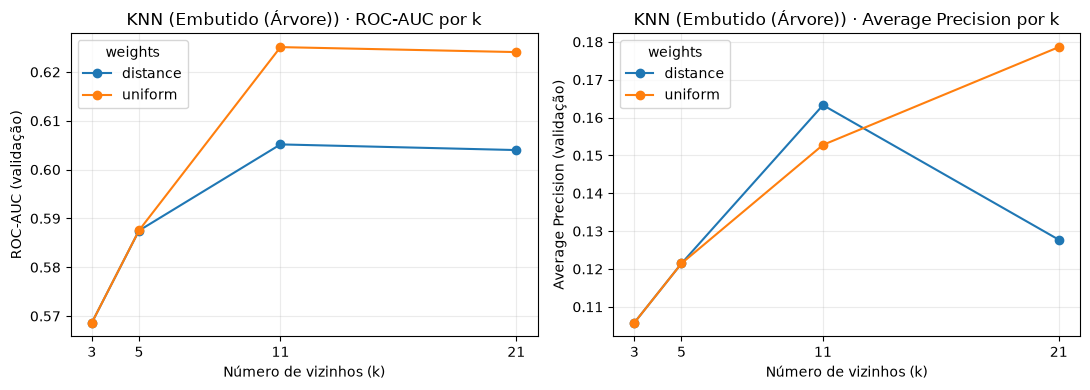

In [8]:
melhor_rep_knn = res_knn.iloc[0]["representacao"]
dados_knn_plot = res_knn.loc[res_knn["representacao"] == melhor_rep_knn].copy()
dados_knn_plot["k"] = dados_knn_plot["parametros"].map(lambda p: p["n_neighbors"])
dados_knn_plot["weights"] = dados_knn_plot["parametros"].map(lambda p: p["weights"])

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))

for voto, grupo in dados_knn_plot.sort_values("k").groupby("weights"):
    eixos[0].plot(grupo["k"], grupo["roc_auc_val"], marker="o", label=voto)
    eixos[1].plot(grupo["k"], grupo["average_precision_val"], marker="o", label=voto)

eixos[0].set(
    xlabel="Número de vizinhos (k)",
    ylabel="ROC-AUC (validação)",
    title=f"KNN ({melhor_rep_knn}) · ROC-AUC por k",
)
eixos[1].set(
    xlabel="Número de vizinhos (k)",
    ylabel="Average Precision (validação)",
    title=f"KNN ({melhor_rep_knn}) · Average Precision por k",
)

for eixo in eixos:
    eixo.set_xticks([3, 5, 11, 21])
    eixo.grid(alpha=0.25)
    eixo.legend(title="weights")

plt.tight_layout()
plt.show()

## 7. Árvore de Decisão

Busca de hiperparâmetros (`max_depth`, `min_samples_leaf` e `class_weight`) sobre a melhor representação da árvore.

In [9]:
res_arvore, oof_arvore = avaliar_modelo_cv(
    FAMILIA_ARVORE,
    treinar_arvore_decisao,
    configuracoes_arvore(SEMENTE),
    folds_por_representacao,
    [melhor_rep_por_familia[FAMILIA_ARVORE]],
    len(y_train),
)

display(res_arvore[COLUNAS_TABELA].round(4))

,representacao,parametros_texto,average_precision_val,roc_auc_val,f1_val,precisao_val,recall_val,acuracia_val,roc_auc_treino
0,One-hot completo,"max_depth=8, min_samples_leaf=1, class_weight=...",0.1276,0.6034,0.2887,0.3200,0.27,0.9951,0.9930
1,One-hot completo,"max_depth=None, min_samples_leaf=1, class_weig...",0.1194,0.6334,0.2706,0.2819,0.27,0.9941,0.9999
2,One-hot completo,"max_depth=None, min_samples_leaf=8, class_weig...",0.1122,0.6577,0.0000,0.0000,0.00,0.9962,0.9910
3,One-hot completo,"max_depth=8, min_samples_leaf=8, class_weight=...",0.1116,0.6280,0.0000,0.0000,0.00,0.9962,0.9847
4,One-hot completo,"max_depth=None, min_samples_leaf=8, class_weig...",0.1090,0.6619,0.0715,0.0402,0.35,0.9653,0.9898
5,One-hot completo,"max_depth=4, min_samples_leaf=8, class_weight=...",0.1085,0.6702,0.0000,0.0000,0.00,0.9962,0.8633
6,One-hot completo,"max_depth=8, min_samples_leaf=8, class_weight=...",0.1068,0.6769,0.0640,0.0354,0.39,0.9535,0.9878
7,One-hot completo,"max_depth=4, min_samples_leaf=1, class_weight=...",0.1011,0.6294,0.1810,0.3667,0.13,0.9955,0.8639
8,One-hot completo,"max_depth=4, min_samples_leaf=1, class_weight=...",0.0929,0.6709,0.0731,0.0401,0.54,0.9222,0.9233
9,One-hot completo,"max_depth=4, min_samples_leaf=8, class_weight=...",0.0621,0.6691,0.0666,0.0363,0.54,0.9172,0.9213


## 8. Random Forest

Busca de hiperparâmetros (200 árvores, `max_depth`, `min_samples_leaf` e `class_weight`) sobre a melhor representação da Random Forest.

In [10]:
res_rf, oof_rf = avaliar_modelo_cv(
    FAMILIA_RF,
    treinar_random_forest,
    configuracoes_rf(SEMENTE),
    folds_por_representacao,
    [melhor_rep_por_familia[FAMILIA_RF]],
    len(y_train),
)

display(res_rf[COLUNAS_TABELA].round(4))

,representacao,parametros_texto,average_precision_val,roc_auc_val,f1_val,precisao_val,recall_val,acuracia_val,roc_auc_treino
0,Informação mútua (k=50),"n_estimators=200, max_depth=6, min_samples_lea...",0.2417,0.9310,0.0000,0.0000,0.00,0.9962,0.9878
1,Informação mútua (k=50),"n_estimators=200, max_depth=15, min_samples_le...",0.2378,0.9246,0.0000,0.0000,0.00,0.9962,0.9922
2,Informação mútua (k=50),"n_estimators=200, max_depth=None, min_samples_...",0.2209,0.9230,0.0000,0.0000,0.00,0.9962,0.9927
3,Informação mútua (k=50),"n_estimators=200, max_depth=15, min_samples_le...",0.2166,0.9030,0.0736,0.0392,0.62,0.9408,0.9947
4,Informação mútua (k=50),"n_estimators=200, max_depth=6, min_samples_lea...",0.2079,0.8981,0.0807,0.0431,0.67,0.9385,0.9877
5,Informação mútua (k=50),"n_estimators=200, max_depth=None, min_samples_...",0.2066,0.9070,0.0670,0.0357,0.57,0.9378,0.9964
6,Informação mútua (k=50),"n_estimators=200, max_depth=6, min_samples_lea...",0.2034,0.8742,0.0751,0.0409,0.49,0.9526,0.9945
7,Informação mútua (k=50),"n_estimators=200, max_depth=6, min_samples_lea...",0.1863,0.9262,0.0000,0.0000,0.00,0.9962,0.9948
8,Informação mútua (k=50),"n_estimators=200, max_depth=15, min_samples_le...",0.1724,0.8484,0.1238,0.2667,0.09,0.9958,0.9994
9,Informação mútua (k=50),"n_estimators=200, max_depth=15, min_samples_le...",0.1516,0.8567,0.1302,0.1067,0.17,0.9899,0.9994


## 9. Multilayer Perceptron (MLP)

Busca de arquiteturas (`(32,)`, `(64,)`, `(64, 32)`) e regularização L2 (`alpha`) sobre a melhor representação da MLP.

In [11]:
res_mlp, oof_mlp = avaliar_modelo_cv(
    FAMILIA_MLP,
    treinar_mlp,
    configuracoes_mlp(SEMENTE),
    folds_por_representacao,
    [melhor_rep_por_familia[FAMILIA_MLP]],
    len(y_train),
)

display(res_mlp[[*COLUNAS_TABELA, "avisos_convergencia"]].round(4))

,representacao,parametros_texto,average_precision_val,roc_auc_val,f1_val,precisao_val,recall_val,acuracia_val,roc_auc_treino,avisos_convergencia
0,One-hot completo,"hidden_layer_sizes=(32,), alpha=0.0001, max_it...",0.2970,0.9212,0.0571,0.0667,0.05,0.9960,0.9924,0
1,One-hot completo,"hidden_layer_sizes=(64,), alpha=0.0001, max_it...",0.2867,0.9200,0.1905,0.4667,0.13,0.9964,0.9957,0
2,One-hot completo,"hidden_layer_sizes=(64,), alpha=0.01, max_iter...",0.2725,0.9267,0.2000,0.5000,0.13,0.9965,0.9915,0
3,One-hot completo,"hidden_layer_sizes=(32,), alpha=0.01, max_iter...",0.2442,0.9316,0.0667,0.1000,0.05,0.9962,0.9880,0
4,One-hot completo,"hidden_layer_sizes=(64, 32), alpha=0.01, max_i...",0.2229,0.9063,0.1167,0.2500,0.09,0.9957,0.9999,0
5,One-hot completo,"hidden_layer_sizes=(64, 32), alpha=0.0001, max...",0.1907,0.9090,0.1167,0.2500,0.09,0.9953,0.9999,0


# Parte II — Comparação na validação cruzada

## 10. Tabela comparativa dos finalistas

In [12]:
resultados_familias = {
    "Referência (Majoritário)": (res_referencia, oof_referencia, treinar_referencia),
    FAMILIA_KNN: (res_knn, oof_knn, treinar_knn),
    FAMILIA_ARVORE: (res_arvore, oof_arvore, treinar_arvore_decisao),
    FAMILIA_RF: (res_rf, oof_rf, treinar_random_forest),
    FAMILIA_MLP: (res_mlp, oof_mlp, treinar_mlp),
}

finalistas_linhas = []
oof_finalistas = {}

for nome_familia, (tabela, oof_dict, _) in resultados_familias.items():
    melhor = tabela.iloc[0]
    finalistas_linhas.append(melhor)
    oof_finalistas[nome_familia] = oof_dict[int(melhor["id_config"])]

finalistas = pd.DataFrame(finalistas_linhas).reset_index(drop=True)

colunas_comparacao = [
    "familia",
    "representacao",
    "parametros_texto",
    "average_precision_val",
    "roc_auc_val",
    "f1_val",
    "precisao_val",
    "recall_val",
    "acuracia_val",
]

display(finalistas[colunas_comparacao].round(4))

,familia,representacao,parametros_texto,average_precision_val,roc_auc_val,f1_val,precisao_val,recall_val,acuracia_val
0,Referência (Majoritário),One-hot completo,padrão,0.0038,0.5000,0.0000,0.0000,0.00,0.9962
1,KNN,Embutido (Árvore),"n_neighbors=21, weights=uniform, metric=euclidean",0.1786,0.6241,0.0000,0.0000,0.00,0.9962
2,Árvore de decisão,One-hot completo,"max_depth=8, min_samples_leaf=1, class_weight=...",0.1276,0.6034,0.2887,0.3200,0.27,0.9951
3,Random Forest,Informação mútua (k=50),"n_estimators=200, max_depth=6, min_samples_lea...",0.2417,0.9310,0.0000,0.0000,0.00,0.9962
4,MLP,One-hot completo,"hidden_layer_sizes=(32,), alpha=0.0001, max_it...",0.2970,0.9212,0.0571,0.0667,0.05,0.9960


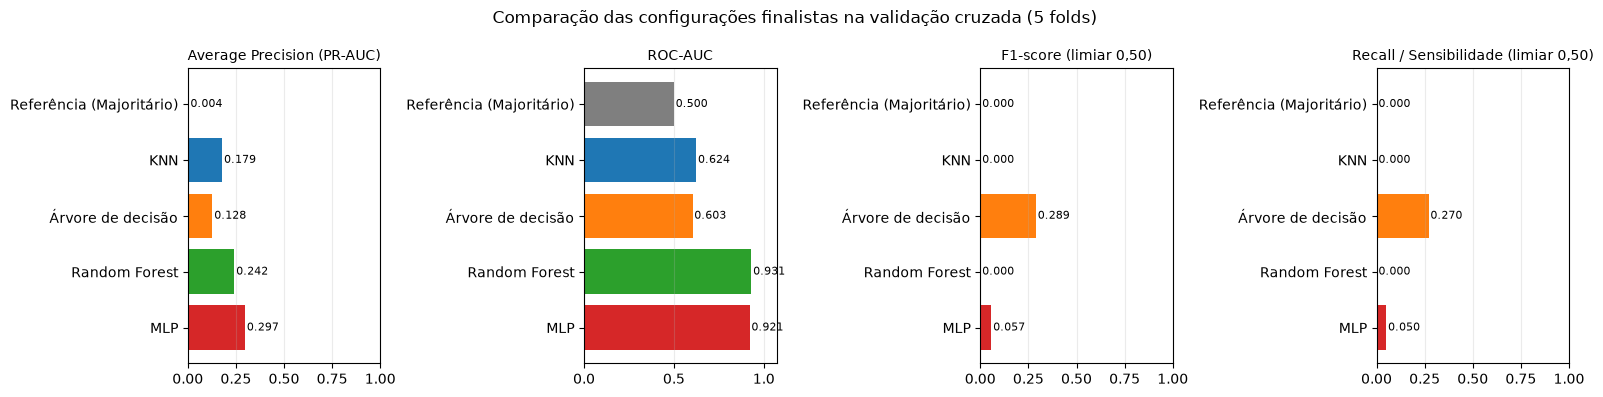

In [13]:
metricas_grafico = [
    ("average_precision_val", "Average Precision (PR-AUC)"),
    ("roc_auc_val", "ROC-AUC"),
    ("f1_val", "F1-score (limiar 0,50)"),
    ("recall_val", "Recall / Sensibilidade (limiar 0,50)"),
]

fig, eixos = plt.subplots(1, 4, figsize=(16, 4))
cores = ["#7f7f7f", "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for eixo, (coluna, titulo) in zip(eixos, metricas_grafico):
    valores = finalistas[coluna].to_numpy()
    eixo.barh(finalistas["familia"], valores, color=cores[: len(finalistas)])
    eixo.set_title(titulo, fontsize=10)
    eixo.set_xlim(0, max(1.0, float(np.nanmax(valores)) * 1.15))
    eixo.invert_yaxis()
    eixo.grid(axis="x", alpha=0.25)
    for pos, val in enumerate(valores):
        eixo.text(val + 0.01, pos, f"{val:.3f}", va="center", fontsize=8)

fig.suptitle("Comparação das configurações finalistas na validação cruzada (5 folds)")
plt.tight_layout()
plt.show()

## 11. Matrizes de confusão (limiar padrão `0,50`)

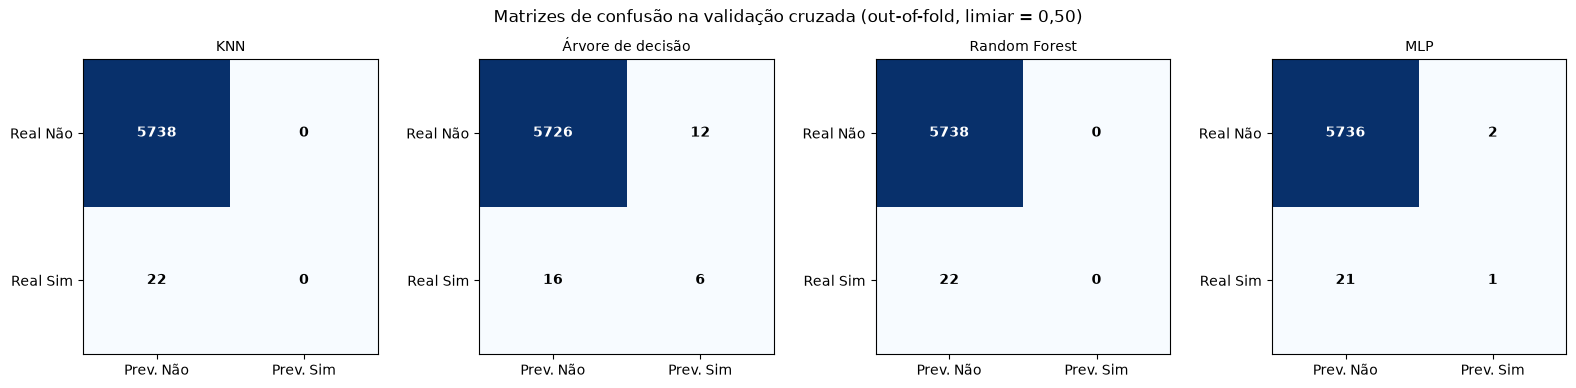

,familia,VP (óbito detectado),FN (óbito perdido),FP (alerta falso),VN (não óbito correto)
0,KNN,0,22,0,5738
1,Árvore de decisão,6,16,12,5726
2,Random Forest,0,22,0,5738
3,MLP,1,21,2,5736


In [14]:
familias_modelos = [FAMILIA_KNN, FAMILIA_ARVORE, FAMILIA_RF, FAMILIA_MLP]

fig, eixos = plt.subplots(1, 4, figsize=(16, 3.8))
resumo_erros = []

for eixo, nome in zip(eixos, familias_modelos):
    probs = oof_finalistas[nome]
    preds = (probs >= 0.5).astype(int)
    cm = confusion_matrix(y_train, preds, labels=[0, 1])
    vn, fp, fn, vp = cm.ravel()
    resumo_erros.append({
        "familia": nome,
        "VP (óbito detectado)": int(vp),
        "FN (óbito perdido)": int(fn),
        "FP (alerta falso)": int(fp),
        "VN (não óbito correto)": int(vn),
    })

    eixo.imshow(cm, cmap="Blues")
    eixo.set_title(nome, fontsize=10)
    eixo.set_xticks([0, 1], labels=["Prev. Não", "Prev. Sim"])
    eixo.set_yticks([0, 1], labels=["Real Não", "Real Sim"])
    limite = cm.max() / 2.0
    for i in range(2):
        for j in range(2):
            cor_texto = "white" if cm[i, j] > limite else "black"
            eixo.text(j, i, f"{cm[i, j]}", ha="center", va="center", color=cor_texto, fontweight="bold")

fig.suptitle("Matrizes de confusão na validação cruzada (out-of-fold, limiar = 0,50)")
plt.tight_layout()
plt.show()

display(pd.DataFrame(resumo_erros))

## 12. Curvas ROC e Precisão-Recall (validação cruzada)

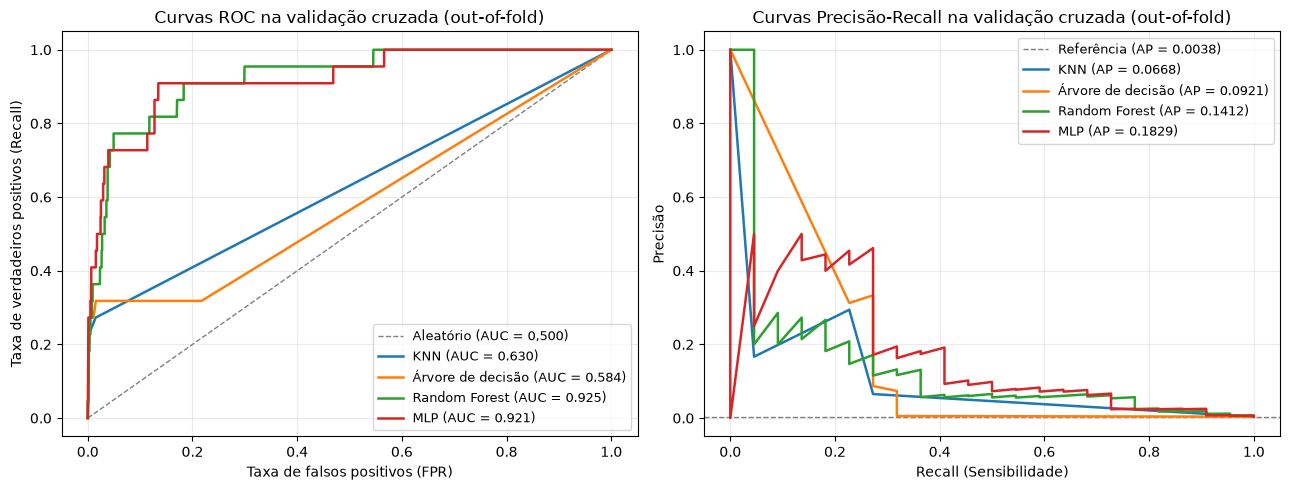

In [15]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

eixos[0].plot([0, 1], [0, 1], "--", color="gray", linewidth=1, label="Aleatório (AUC = 0,500)")
prevalencia_treino = float(y_train.mean())
eixos[1].axhline(
    prevalencia_treino,
    linestyle="--",
    color="gray",
    linewidth=1,
    label=f"Referência (AP = {prevalencia_treino:.4f})",
)

for nome in familias_modelos:
    probs = oof_finalistas[nome]
    fpr, tpr, _ = roc_curve(y_train, probs)
    auc_oof = roc_auc_score(y_train, probs)
    eixos[0].plot(fpr, tpr, linewidth=1.8, label=f"{nome} (AUC = {auc_oof:.3f})")

    prec, rec, _ = precision_recall_curve(y_train, probs)
    ap_oof = average_precision_score(y_train, probs)
    eixos[1].plot(rec, prec, linewidth=1.8, label=f"{nome} (AP = {ap_oof:.4f})")

eixos[0].set(
    xlabel="Taxa de falsos positivos (FPR)",
    ylabel="Taxa de verdadeiros positivos (Recall)",
    title="Curvas ROC na validação cruzada (out-of-fold)",
)
eixos[1].set(
    xlabel="Recall (Sensibilidade)",
    ylabel="Precisão",
    title="Curvas Precisão-Recall na validação cruzada (out-of-fold)",
)

for eixo in eixos:
    eixo.grid(alpha=0.25)
    eixo.legend(fontsize=9)

plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "roc_pr_validacao.png", dpi=135)
plt.show()

### 12.1 Calibração de limiar orientada a Recall (validação cruzada)

Comparamos na CV os cortes **Padrão (`0,50`)**, **Máximo `F1`**, **Máximo `F2`** (prioriza Recall 2×) e **Triagem `Recall ≥ 80%`**.

In [16]:
limiares_cv = {}
limiares_f2_cv = {}
limiares_r80_cv = {}
linhas_limiar = []

for nome in familias_modelos:
    probs = oof_finalistas[nome]
    lim_f1 = melhor_limiar_f1(y_train, probs)
    lim_f2 = melhor_limiar_fbeta(y_train, probs, beta=2.0)
    lim_r80 = limiar_recall_minimo(y_train, probs, recall_alvo=0.80)

    limiares_cv[nome] = lim_f1
    limiares_f2_cv[nome] = lim_f2
    limiares_r80_cv[nome] = lim_r80

    for rotulo, lim in [
        ("Padrão (0,50)", 0.50),
        ("Máximo F1 (CV)", lim_f1),
        ("Máximo F2 (CV)", lim_f2),
        ("Triagem Recall ≥ 80% (CV)", lim_r80),
    ]:
        m = calcular_metricas(y_train, probs, limiar=lim)
        linhas_limiar.append({
            "familia": nome,
            "estrategia": rotulo,
            "limiar": round(lim, 4),
            "recall": m["recall"],
            "precisao": m["precisao"],
            "f2": m["f2"],
            "f1": m["f1"],
            "alertas (%)": m["pct_alertas"],
            "vp": m["vp"],
            "fn": m["fn"],
            "fp": m["fp"],
        })

display(pd.DataFrame(linhas_limiar).round(4))

,familia,estrategia,limiar,recall,precisao,f2,f1,alertas (%),vp,fn,fp
0,KNN,"Padrão (0,50)",0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0,22,0
1,KNN,Máximo F1 (CV),0.0952,0.2273,0.2941,0.2381,0.2564,0.2951,5,17,12
2,KNN,Máximo F2 (CV),0.0952,0.2273,0.2941,0.2381,0.2564,0.2951,5,17,12
3,KNN,Triagem Recall ≥ 80% (CV),0.0000,1.0000,0.0038,0.0188,0.0076,100.0000,22,0,5738
4,Árvore de decisão,"Padrão (0,50)",0.5000,0.2727,0.3333,0.2830,0.3000,0.3125,6,16,12
5,Árvore de decisão,Máximo F1 (CV),0.5000,0.2727,0.3333,0.2830,0.3000,0.3125,6,16,12
6,Árvore de decisão,Máximo F2 (CV),0.5000,0.2727,0.3333,0.2830,0.3000,0.3125,6,16,12
7,Árvore de decisão,Triagem Recall ≥ 80% (CV),0.0000,1.0000,0.0038,0.0188,0.0076,100.0000,22,0,5738
8,Random Forest,"Padrão (0,50)",0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0,22,0
9,Random Forest,Máximo F1 (CV),0.0799,0.2273,0.2083,0.2232,0.2174,0.4167,5,17,19


## 13. Diagnóstico de overfitting (treino vs. validação)

,familia,representacao,roc_auc_treino,roc_auc_val,average_precision_treino,average_precision_val,f1_treino,f1_val,gap_roc_auc,gap_ap
1,KNN,Embutido (Árvore),0.8523,0.6241,0.2143,0.1786,0.0000,0.0000,0.2282,0.0357
2,Árvore de decisão,One-hot completo,0.9930,0.6034,0.8801,0.1276,0.8433,0.2887,0.3896,0.7525
3,Random Forest,Informação mútua (k=50),0.9878,0.9310,0.3711,0.2417,0.0000,0.0000,0.0568,0.1294
4,MLP,One-hot completo,0.9924,0.9212,0.6824,0.2970,0.4483,0.0571,0.0712,0.3854


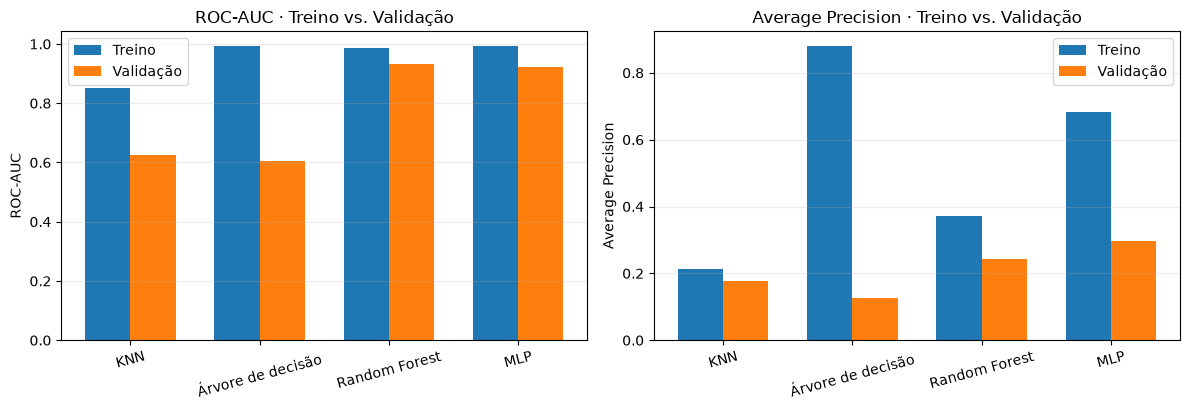

In [17]:
diag_overfit = finalistas.loc[
    finalistas["familia"].isin(familias_modelos),
    [
        "familia",
        "representacao",
        "roc_auc_treino",
        "roc_auc_val",
        "average_precision_treino",
        "average_precision_val",
        "f1_treino",
        "f1_val",
    ],
].copy()

diag_overfit["gap_roc_auc"] = diag_overfit["roc_auc_treino"] - diag_overfit["roc_auc_val"]
diag_overfit["gap_ap"] = (
    diag_overfit["average_precision_treino"] - diag_overfit["average_precision_val"]
)

display(diag_overfit.round(4))

x_pos = np.arange(len(diag_overfit))
largura = 0.35

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2))

eixos[0].bar(x_pos - largura / 2, diag_overfit["roc_auc_treino"], largura, label="Treino")
eixos[0].bar(x_pos + largura / 2, diag_overfit["roc_auc_val"], largura, label="Validação")
eixos[0].set_title("ROC-AUC · Treino vs. Validação")
eixos[0].set_ylabel("ROC-AUC")

eixos[1].bar(
    x_pos - largura / 2,
    diag_overfit["average_precision_treino"],
    largura,
    label="Treino",
)
eixos[1].bar(
    x_pos + largura / 2,
    diag_overfit["average_precision_val"],
    largura,
    label="Validação",
)
eixos[1].set_title("Average Precision · Treino vs. Validação")
eixos[1].set_ylabel("Average Precision")

for eixo in eixos:
    eixo.set_xticks(x_pos, diag_overfit["familia"], rotation=15)
    eixo.grid(axis="y", alpha=0.25)
    eixo.legend()

plt.tight_layout()
plt.show()

# Parte III — Modelo final e avaliação no teste

## 14. Escolha e treinamento do modelo final

Selecionamos a configuração vencedora exclusivamente pela CV e a reajustamos sobre todo o treino (5.760 registros).

In [18]:
candidatos_finais = finalistas.loc[
    finalistas["familia"].isin(familias_modelos)
].sort_values(
    ["average_precision_val", "roc_auc_val", "f1_val"],
    ascending=[False, False, False],
    ignore_index=True,
)

vencedor = candidatos_finais.iloc[0]
familia_vencedora = vencedor["familia"]
rep_vencedora = vencedor["representacao"]
params_vencedor = vencedor["parametros"]
limiar_vencedor_cv = limiares_cv[familia_vencedora]
limiar_vencedor_f2 = limiares_f2_cv[familia_vencedora]
limiar_vencedor_r80 = limiares_r80_cv[familia_vencedora]

print("Família escolhida na validação cruzada:", familia_vencedora)
print("Representação escolhida na CV:", rep_vencedora)
print("Hiperparâmetros:", vencedor["parametros_texto"])
print(f"Average Precision (CV): {vencedor['average_precision_val']:.4f}")
print(f"ROC-AUC (CV): {vencedor['roc_auc_val']:.4f}")
print(f"Limiar calibrado na CV (máximo F1): {limiar_vencedor_cv:.4f}")
print(f"Limiar calibrado na CV (máximo F2, prioriza Recall): {limiar_vencedor_f2:.4f}")
print(f"Limiar calibrado na CV (triagem Recall >= 80%): {limiar_vencedor_r80:.4f}")

modelos_treinados = {}
X_train_por_familia = {}
X_test_por_familia = {}
colunas_por_familia = {}

for linha in candidatos_finais.itertuples(index=False):
    X_tr_mat, X_te_mat, nomes_cols = construir_representacao(
        linha.representacao, X_train, y_train.to_numpy(), X_test
    )
    X_tr_df = pd.DataFrame(X_tr_mat, columns=nomes_cols, index=X_train.index)
    X_te_df = pd.DataFrame(X_te_mat, columns=nomes_cols, index=X_test.index)

    _, _, funcao_treino = resultados_familias[linha.familia]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        modelos_treinados[linha.familia] = funcao_treino(
            X_tr_df,
            y_train,
            **linha.parametros,
        )

    X_train_por_familia[linha.familia] = X_tr_df
    X_test_por_familia[linha.familia] = X_te_df
    colunas_por_familia[linha.familia] = nomes_cols

modelo_final = modelos_treinados[familia_vencedora]
X_train_num = X_train_por_familia[familia_vencedora]
X_test_num = X_test_por_familia[familia_vencedora]

print("\nDimensão da matriz final de treino:", X_train_num.shape)
print("Dimensão da matriz final de teste:", X_test_num.shape)
print("Instância final retornada pelo script:", modelo_final)

Família escolhida na validação cruzada: MLP
Representação escolhida na CV: One-hot completo
Hiperparâmetros: hidden_layer_sizes=(32,), alpha=0.0001, max_iter=300
Average Precision (CV): 0.2970
ROC-AUC (CV): 0.9212
Limiar calibrado na CV (máximo F1): 0.2228
Limiar calibrado na CV (máximo F2, prioriza Recall): 0.0752
Limiar calibrado na CV (triagem Recall >= 80%): 0.0018



Dimensão da matriz final de treino: (5760, 228)
Dimensão da matriz final de teste: (1441, 228)
Instância final retornada pelo script: MLPClassifier(hidden_layer_sizes=(32,), max_iter=300, random_state=42)


## 15. Avaliação final no conjunto de teste

Avaliação única sobre os 1.441 registros de teste (5 óbitos) com os limiares calibrados na CV.

In [19]:
prob_teste_vencedor = probabilidade_positiva(modelo_final, X_test_num)

metricas_teste_05 = calcular_metricas(y_test, prob_teste_vencedor, limiar=0.50)
metricas_teste_f1 = calcular_metricas(y_test, prob_teste_vencedor, limiar=limiar_vencedor_cv)
metricas_teste_f2 = calcular_metricas(y_test, prob_teste_vencedor, limiar=limiar_vencedor_f2)
metricas_teste_r80 = calcular_metricas(y_test, prob_teste_vencedor, limiar=limiar_vencedor_r80)

chaves_metricas = ["average_precision", "roc_auc", "recall", "precisao", "f2", "f1", "pct_alertas", "acuracia"]

comparacao_val_teste = pd.DataFrame([
    {
        "avaliacao": "Validação cruzada (média 5 folds, limiar 0,50)",
        "average_precision": vencedor["average_precision_val"],
        "roc_auc": vencedor["roc_auc_val"],
        "recall": vencedor["recall_val"],
        "precisao": vencedor["precisao_val"],
        "f2": calcular_metricas(y_train, oof_finalistas[familia_vencedora], limiar=0.50)["f2"],
        "f1": vencedor["f1_val"],
        "pct_alertas": calcular_metricas(y_train, oof_finalistas[familia_vencedora], limiar=0.50)["pct_alertas"],
        "acuracia": vencedor["acuracia_val"],
    },
    {
        "avaliacao": "Teste holdout · Padrão (0,50)",
        **{k: metricas_teste_05[k] for k in chaves_metricas},
    },
    {
        "avaliacao": f"Teste holdout · Máximo F1 (limiar CV = {limiar_vencedor_cv:.4f})",
        **{k: metricas_teste_f1[k] for k in chaves_metricas},
    },
    {
        "avaliacao": f"Teste holdout · Máximo F2 (limiar CV = {limiar_vencedor_f2:.4f})",
        **{k: metricas_teste_f2[k] for k in chaves_metricas},
    },
    {
        "avaliacao": f"Teste holdout · Triagem Recall ≥ 80% (limiar CV = {limiar_vencedor_r80:.4f})",
        **{k: metricas_teste_r80[k] for k in chaves_metricas},
    },
])

display(comparacao_val_teste.round(4))

contagens_teste = pd.DataFrame([
    {
        "cenario": rotulo,
        "limiar": round(lim, 4),
        "VP (detectados)": m["vp"],
        "FN (perdidos)": m["fn"],
        "FP (alertas extras)": m["fp"],
        "VN": m["vn"],
        "CATs alertadas (%)": round(m["pct_alertas"], 2),
    }
    for rotulo, lim, m in [
        ("Padrão (0,50)", 0.50, metricas_teste_05),
        ("Máximo F1 (CV)", limiar_vencedor_cv, metricas_teste_f1),
        ("Máximo F2 (CV)", limiar_vencedor_f2, metricas_teste_f2),
        ("Triagem Recall ≥ 80% (CV)", limiar_vencedor_r80, metricas_teste_r80),
    ]
])

display(contagens_teste)

,avaliacao,average_precision,roc_auc,recall,precisao,f2,f1,pct_alertas,acuracia
0,"Validação cruzada (média 5 folds, limiar 0,50)",0.297,0.9212,0.05,0.0667,0.0549,0.0571,0.0521,0.9960
1,"Teste holdout · Padrão (0,50)",0.352,0.9446,0.00,0.0000,0.0000,0.0000,0.0000,0.9965
2,Teste holdout · Máximo F1 (limiar CV = 0.2228),0.352,0.9446,0.20,1.0000,0.2381,0.3333,0.0694,0.9972
3,Teste holdout · Máximo F2 (limiar CV = 0.0752),0.352,0.9446,0.40,0.2000,0.3333,0.2667,0.6940,0.9924
4,Teste holdout · Triagem Recall ≥ 80% (limiar C...,0.352,0.9446,0.80,0.0237,0.1058,0.0460,11.7280,0.8848


,cenario,limiar,VP (detectados),FN (perdidos),FP (alertas extras),VN,CATs alertadas (%)
0,"Padrão (0,50)",0.5000,0,5,0,1436,0.00
1,Máximo F1 (CV),0.2228,1,4,0,1436,0.07
2,Máximo F2 (CV),0.0752,2,3,8,1428,0.69
3,Triagem Recall ≥ 80% (CV),0.0018,4,1,165,1271,11.73


### 15.1 Matrizes de confusão e curvas ROC / PR no teste

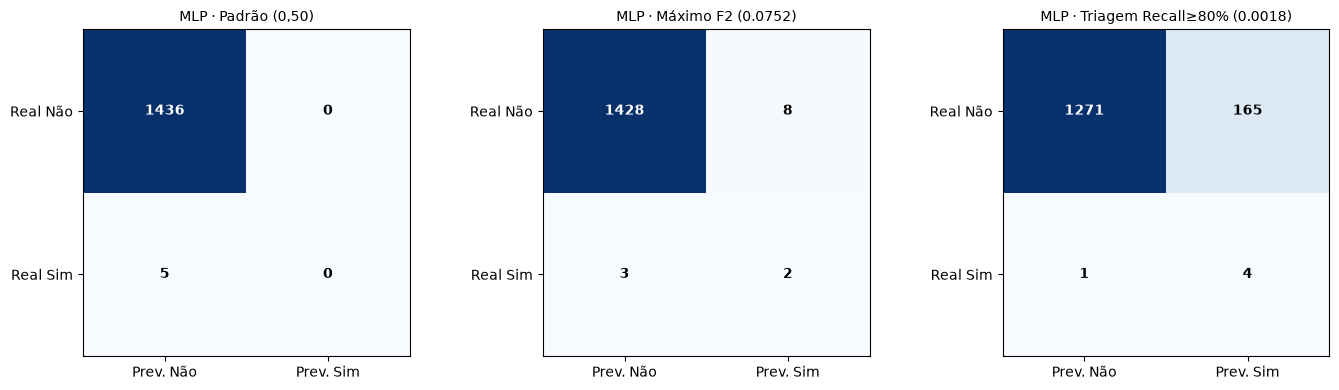

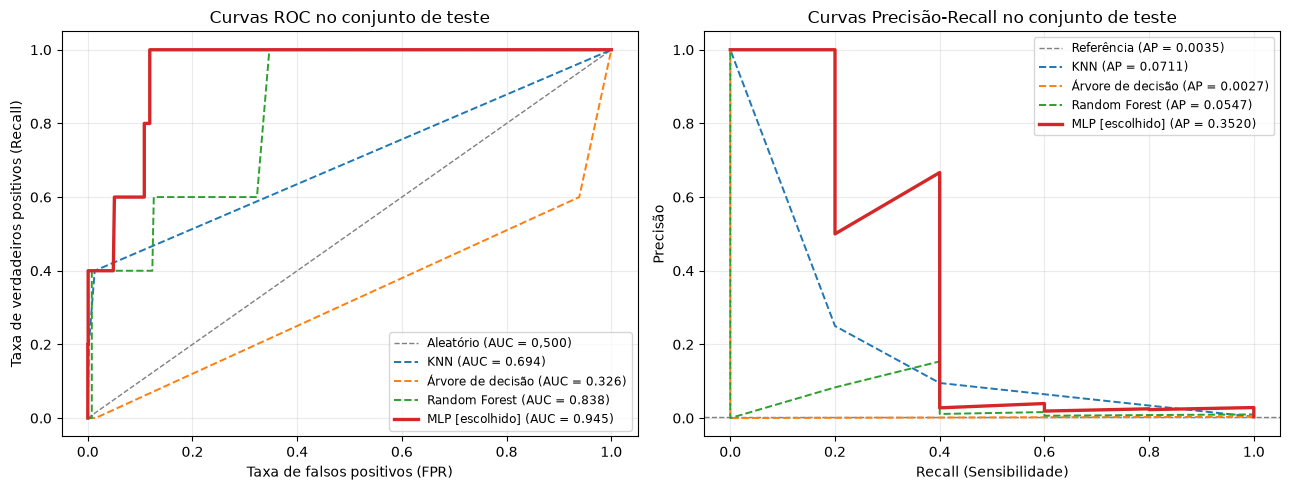

In [20]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 4))

for eixo, (titulo, lim) in zip(
    eixos,
    [
        (f"{familia_vencedora} · Padrão (0,50)", 0.50),
        (f"{familia_vencedora} · Máximo F2 ({limiar_vencedor_f2:.4f})", limiar_vencedor_f2),
        (f"{familia_vencedora} · Triagem Recall≥80% ({limiar_vencedor_r80:.4f})", limiar_vencedor_r80),
    ],
):
    cm = confusion_matrix(y_test, (prob_teste_vencedor >= lim).astype(int), labels=[0, 1])
    eixo.imshow(cm, cmap="Blues")
    eixo.set_title(titulo, fontsize=10)
    eixo.set_xticks([0, 1], labels=["Prev. Não", "Prev. Sim"])
    eixo.set_yticks([0, 1], labels=["Real Não", "Real Sim"])
    limite = cm.max() / 2.0
    for i in range(2):
        for j in range(2):
            cor = "white" if cm[i, j] > limite else "black"
            eixo.text(j, i, f"{cm[i, j]}", ha="center", va="center", color=cor, fontweight="bold")

plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "matriz_confusao_teste.png", dpi=135)
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
eixos[0].plot([0, 1], [0, 1], "--", color="gray", linewidth=1, label="Aleatório (AUC = 0,500)")
prevalencia_teste = float(y_test.mean())
eixos[1].axhline(
    prevalencia_teste,
    linestyle="--",
    color="gray",
    linewidth=1,
    label=f"Referência (AP = {prevalencia_teste:.4f})",
)

for nome in familias_modelos:
    prob_t = probabilidade_positiva(modelos_treinados[nome], X_test_por_familia[nome])
    fpr, tpr, _ = roc_curve(y_test, prob_t)
    auc_t = roc_auc_score(y_test, prob_t)
    estilo = "-" if nome == familia_vencedora else "--"
    espessura = 2.4 if nome == familia_vencedora else 1.4
    sufixo = " [escolhido]" if nome == familia_vencedora else ""

    eixos[0].plot(fpr, tpr, linestyle=estilo, linewidth=espessura, label=f"{nome}{sufixo} (AUC = {auc_t:.3f})")

    prec, rec, _ = precision_recall_curve(y_test, prob_t)
    ap_t = average_precision_score(y_test, prob_t)
    eixos[1].plot(rec, prec, linestyle=estilo, linewidth=espessura, label=f"{nome}{sufixo} (AP = {ap_t:.4f})")

eixos[0].set(
    xlabel="Taxa de falsos positivos (FPR)",
    ylabel="Taxa de verdadeiros positivos (Recall)",
    title="Curvas ROC no conjunto de teste",
)
eixos[1].set(
    xlabel="Recall (Sensibilidade)",
    ylabel="Precisão",
    title="Curvas Precisão-Recall no conjunto de teste",
)

for eixo in eixos:
    eixo.grid(alpha=0.25)
    eixo.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "roc_pr_teste.png", dpi=135)
plt.show()

### 15.2 Atributos mais influentes (quando aplicável)

In [21]:
if hasattr(modelo_final, "feature_importances_"):
    importancias_finais = (
        pd.DataFrame({
            "indicador": X_train_num.columns,
            "importancia": modelo_final.feature_importances_,
        })
        .sort_values("importancia", ascending=False)
        .head(15)
    )
    display(importancias_finais.reset_index(drop=True))
else:
    print(
        f"O modelo final ({familia_vencedora}) não expõe feature_importances_ diretamente."
    )

O modelo final (MLP) não expõe feature_importances_ diretamente.


## 16. Síntese

A discussão detalhada sobre os resultados, trade-off entre Recall e volume de alertas, limitações da amostra (27 óbitos no semestre) e próximos passos encontra-se em [`relatorio_modelos_supervisionados.md`](relatorio_modelos_supervisionados.md).

## 17. Referências

Documentação do `scikit-learn`: [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html), [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html), [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html), [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html) e [Métricas de classificação](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).